In [ ]:
# Execute this first 
#
#  * trigger notebook styling
#  * check if notebook had been modified since its distribution
# 
# Note: executing any cells before this modifies the notebook.
# 
%run src/init_notebooks.py
hide_toggle()
#check_notebook()

In [ ]:
import nglview as ng
import pandas as pd
import mdtraj as md
import numpy as np

In [31]:
# Go To Methane directory and use 94K
%cd ~/gromacs/build/Titan/Ammonia/94K

/home/dragns/gromacs/build/Titan/Ammonia/94K


In [32]:
!ls

94_Indexed	  AmmoniaDOS_setup  convert_dos.py  nvt.mdp	    test
Ammonia94K.ipynb  ammonia.pdb	    em.mdp	    production.mdp  topol.top
AmmoniaDOS.py	  ammonidaBonds.py  npt.mdp	    Result1


In [33]:
# Load and view the .pdb or .gro file with the following lines
view = ng.show_structure_file("ammonia.pdb")
view

NGLWidget()

In [44]:
# Replicate Ammonia Unit Cells
!gmx genconf -f ammonia.pdb -o Ammonia.gro -nbox 5 5 5

               :-) GROMACS - gmx genconf, 2024.3-conda_forge (-:

Executable:   /home/dragns/miniconda3/envs/md-intro-tutorial/bin.SSE2/gmx
Data prefix:  /home/dragns/miniconda3/envs/md-intro-tutorial
Working dir:  /home/dragns/gromacs/build/Titan/Ammonia/94K
Command line:
  gmx genconf -f ammonia.pdb -o Ammonia.gro -nbox 5 5 5


GROMACS reminds you: "Everything Must Go" (Red Hot Chili Peppers)



In [45]:
# View the system
view = ng.show_structure_file("Ammonia.gro")
view.clear_representations()
view.add_ball_and_stick()
view.camera = 'orthographic'
view.center()
view

NGLWidget()

In [46]:
!tail -1 Ammonia.gro

   2.56900   2.56900   2.56900


In [48]:
#Energy Minimization
!gmx grompp -f em.mdp -c Ammonia.gro -p topol.top -o em.tpr
!gmx mdrun -v -deffnm em -ntmpi 1 -ntomp 1

                :-) GROMACS - gmx grompp, 2024.3-conda_forge (-:

Executable:   /home/dragns/miniconda3/envs/md-intro-tutorial/bin.SSE2/gmx
Data prefix:  /home/dragns/miniconda3/envs/md-intro-tutorial
Working dir:  /home/dragns/gromacs/build/Titan/Ammonia/94K
Command line:
  gmx grompp -f em.mdp -c Ammonia.gro -p topol.top -o em.tpr

Setting the LD random seed to -598016513

Generated 3 of the 3 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 3 of the 3 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'NH3'
Analysing residue names:
There are:   500      Other residues
Analysing residues not classified as Protein/DNA/RNA/Water and splitting into groups...
Number of degrees of freedom in T-Coupling group rest is 5997.00
The integrator does not provide a ensemble temperature, there is no system ensemble temperature

The largest distance between excluded atoms is 0.164 nm between atom 30 and 32
Calculating fourier grid dimensions

                :-) GROMACS - gmx energy, 2024.3-conda_forge (-:

Executable:   /home/dragns/miniconda3/envs/md-intro-tutorial/bin.SSE2/gmx
Data prefix:  /home/dragns/miniconda3/envs/md-intro-tutorial
Working dir:  /home/dragns/gromacs/build/Titan/Ammonia/94K
Command line:
  gmx energy -f em.edr -o potential.xvg -xvg none

Opened em.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  LJ-(SR)          4  Disper.-corr. 
  5  Coulomb-(SR)     6  Coul.-recip.     7  Potential        8  Pres.-DC      
  9  Pressure        10  Vir-XX          11  Vir-XY          12  Vir-XZ        
 13  Vir-YX          14  Vir-YY          15  Vir-YZ          16  Vir-ZX        
 17  Vir-ZY          18  Vir-ZZ          19  Pres-XX         20  Pres-

<Axes: xlabel='step'>

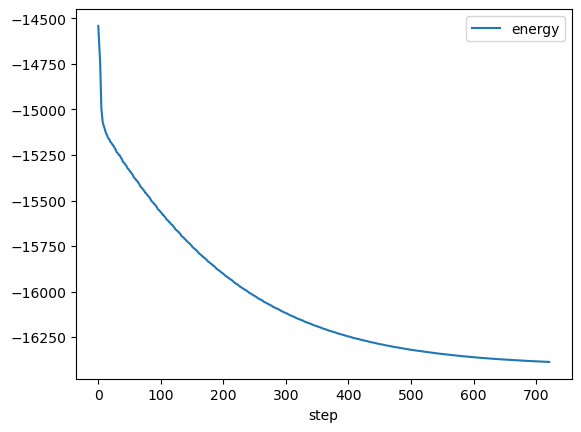

In [49]:
#Analyze results of EM
!printf "Potential\n0\n" | gmx energy -f em.edr -o potential.xvg -xvg none
# Print graph
df = pd.read_csv('potential.xvg', sep='\\s+', header=None, names=['step','energy'])
df.plot('step')

In [50]:
# Temperature EQ T=94K
!gmx grompp -f nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr 
!gmx mdrun -ntmpi 1 -ntomp 6 -v -deffnm nvt

                :-) GROMACS - gmx grompp, 2024.3-conda_forge (-:

Executable:   /home/dragns/miniconda3/envs/md-intro-tutorial/bin.SSE2/gmx
Data prefix:  /home/dragns/miniconda3/envs/md-intro-tutorial
Working dir:  /home/dragns/gromacs/build/Titan/Ammonia/94K
Command line:
  gmx grompp -f nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr

Ignoring obsolete mdp entry 'ns_type'
Setting the LD random seed to -8675526

Generated 3 of the 3 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 3 of the 3 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'NH3'

Setting gen_seed to -50339283

Velocities were taken from a Maxwell distribution at 94 K
Analysing residue names:
There are:   500      Other residues
Analysing residues not classified as Protein/DNA/RNA/Water and splitting into groups...
Number of degrees of freedom in T-Coupling group System is 5997.00

The largest distance between excluded atoms is 0.162 nm between atom 759 an

                :-) GROMACS - gmx energy, 2024.3-conda_forge (-:

Executable:   /home/dragns/miniconda3/envs/md-intro-tutorial/bin.SSE2/gmx
Data prefix:  /home/dragns/miniconda3/envs/md-intro-tutorial
Working dir:  /home/dragns/gromacs/build/Titan/Ammonia/94K
Command line:
  gmx energy -f nvt.edr -o temperature.xvg -xvg none -b 20

Opened nvt.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  LJ-(SR)          4  Disper.-corr. 
  5  Coulomb-(SR)     6  Coul.-recip.     7  Potential        8  Kinetic-En.   
  9  Total-Energy    10  Conserved-En.   11  Temperature     12  Pres.-DC      
 13  Pressure        14  Vir-XX          15  Vir-XY          16  Vir-XZ        
 17  Vir-YX          18  Vir-YY          19  Vir-YZ         

<Axes: xlabel='time'>

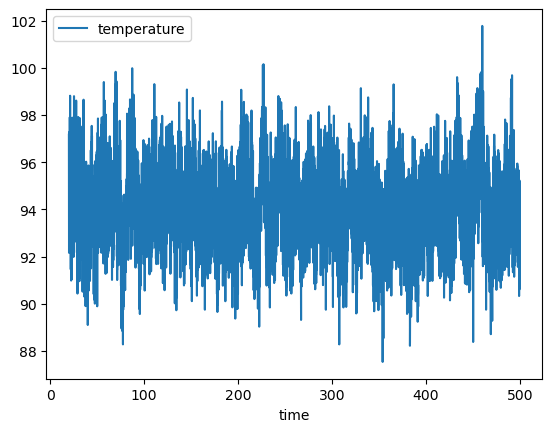

In [51]:
# Analyze Temp run
!echo "Temperature" | gmx energy -f nvt.edr -o temperature.xvg -xvg none -b 20
# Plot Temp data
df = pd.read_csv('temperature.xvg', sep='\\s+', header=None, names=['time','temperature'])
df.plot('time')


In [53]:
# Pressure EQ P = 1.5 bars
!gmx grompp -f npt.mdp -c nvt.gro -r nvt.gro -t nvt.cpt -p topol.top -o npt.tpr
!gmx mdrun -ntmpi 1 -ntomp 6 -v -deffnm npt

                :-) GROMACS - gmx grompp, 2024.3-conda_forge (-:

Executable:   /home/dragns/miniconda3/envs/md-intro-tutorial/bin.SSE2/gmx
Data prefix:  /home/dragns/miniconda3/envs/md-intro-tutorial
Working dir:  /home/dragns/gromacs/build/Titan/Ammonia/94K
Command line:
  gmx grompp -f npt.mdp -c nvt.gro -r nvt.gro -t nvt.cpt -p topol.top -o npt.tpr

Ignoring obsolete mdp entry 'ns_type'
Setting the LD random seed to 2142894543

Generated 3 of the 3 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 3 of the 3 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'NH3'
Analysing residue names:
There are:   500      Other residues
Analysing residues not classified as Protein/DNA/RNA/Water and splitting into groups...
Number of degrees of freedom in T-Coupling group System is 5997.00

The largest distance between excluded atoms is 0.172 nm between atom 1419 and 1420

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 94

                :-) GROMACS - gmx energy, 2024.3-conda_forge (-:

Executable:   /home/dragns/miniconda3/envs/md-intro-tutorial/bin.SSE2/gmx
Data prefix:  /home/dragns/miniconda3/envs/md-intro-tutorial
Working dir:  /home/dragns/gromacs/build/Titan/Ammonia/94K
Command line:
  gmx energy -f npt.edr -o pressure.xvg -xvg none

Opened npt.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  LJ-(SR)          4  Disper.-corr. 
  5  Coulomb-(SR)     6  Coul.-recip.     7  Potential        8  Kinetic-En.   
  9  Total-Energy    10  Conserved-En.   11  Temperature     12  Pres.-DC      
 13  Pressure        14  Box-X           15  Box-Y           16  Box-Z         
 17  Volume          18  Density         19  pV              20  Enth

<Axes: xlabel='time'>

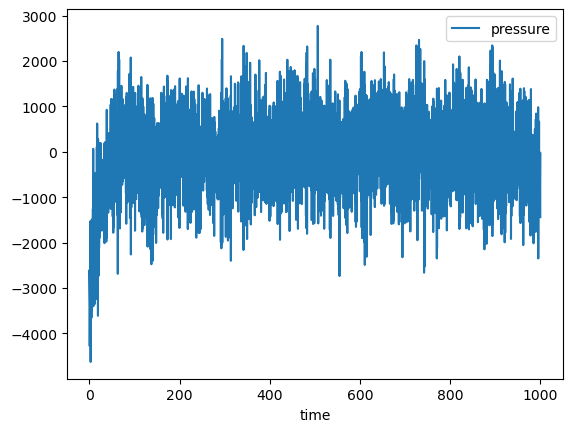

In [54]:
# Analyze Pressure Data
!echo "Pressure" | gmx energy -f npt.edr -o pressure.xvg -xvg none
df = pd.read_csv('pressure.xvg', sep='\\s+', header=None, names=['time','pressure'])
df.plot('time')

                :-) GROMACS - gmx energy, 2024.3-conda_forge (-:

Executable:   /home/dragns/miniconda3/envs/md-intro-tutorial/bin.SSE2/gmx
Data prefix:  /home/dragns/miniconda3/envs/md-intro-tutorial
Working dir:  /home/dragns/gromacs/build/Titan/Ammonia/94K
Command line:
  gmx energy -f npt.edr -o density.xvg -xvg none

Opened npt.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  LJ-(SR)          4  Disper.-corr. 
  5  Coulomb-(SR)     6  Coul.-recip.     7  Potential        8  Kinetic-En.   
  9  Total-Energy    10  Conserved-En.   11  Temperature     12  Pres.-DC      
 13  Pressure        14  Box-X           15  Box-Y           16  Box-Z         
 17  Volume          18  Density         19  pV              20  Entha

<Axes: xlabel='time'>

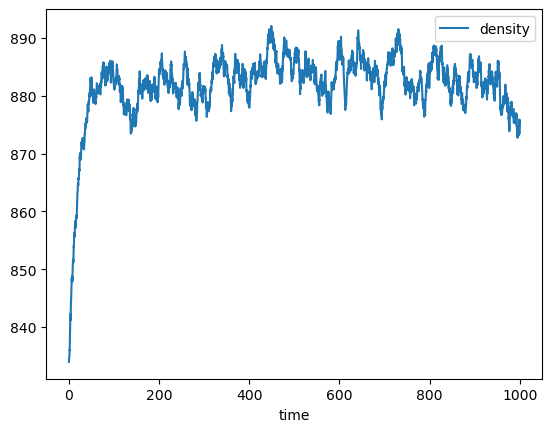

In [55]:
# Look at density of system
!echo "Density" | gmx energy -f npt.edr -o density.xvg -xvg none
#Plot density
df = pd.read_csv('density.xvg', sep='\\s+', header=None, names=['time','density'])
df.plot('time')

In [56]:
!tail -1 npt.gro

   2.52960   2.52960   2.52960


In [57]:
#Production Run
!gmx grompp -f production.mdp -c npt.gro -t npt.cpt -p topol.top -o md.tpr
!gmx mdrun -ntmpi 1 -ntomp 6 -v -deffnm md

                :-) GROMACS - gmx grompp, 2024.3-conda_forge (-:

Executable:   /home/dragns/miniconda3/envs/md-intro-tutorial/bin.SSE2/gmx
Data prefix:  /home/dragns/miniconda3/envs/md-intro-tutorial
Working dir:  /home/dragns/gromacs/build/Titan/Ammonia/94K
Command line:
  gmx grompp -f production.mdp -c npt.gro -t npt.cpt -p topol.top -o md.tpr

Ignoring obsolete mdp entry 'ns_type'
Setting the LD random seed to -4207649

Generated 3 of the 3 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 3 of the 3 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'NH3'
Analysing residue names:
There are:   500      Other residues
Analysing residues not classified as Protein/DNA/RNA/Water and splitting into groups...
Number of degrees of freedom in T-Coupling group rest is 5997.00
The integrator does not provide a ensemble temperature, there is no system ensemble temperature

The largest distance between excluded atoms is 0.172 nm between

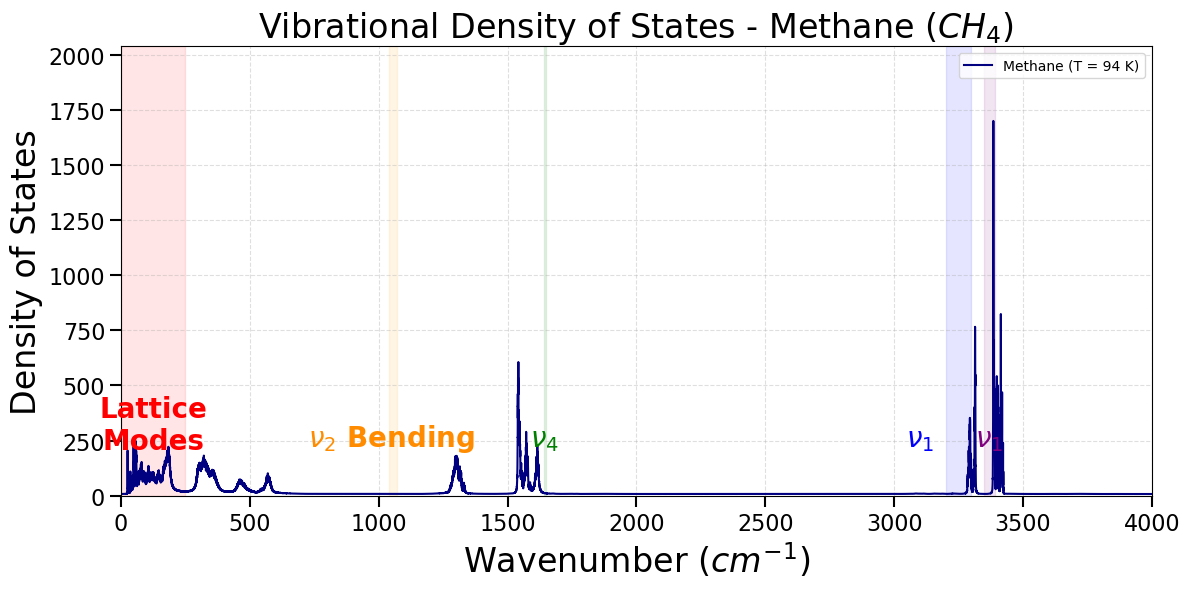

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the data 
# Added '#' to comment handling as GROMACS files use both @ and #
df_dos = pd.read_csv(
    'dos.xvg', 
    sep=r'\s+', 
    comment='@', 
    header=None,
    on_bad_lines='skip',
    engine='python'
)

# 2. Convert everything to numeric
df_dos = df_dos.apply(pd.to_numeric, errors='coerce')

# 3. Drop rows that are completely NaN and filter out '#' comment lines
df_dos = df_dos.dropna(how='all').reset_index(drop=True)

# 4. Use first two columns: Frequency and DOS
df_dos = df_dos.iloc[:, :2] 
df_dos.columns = ['freq', 'dos']

# 5. Convert Frequency (ps^-1) to Wavenumber (cm^-1)
# 1 ps^-1 = 33.35641 cm^-1
df_dos['freq_cm'] = df_dos['freq'] * 33.35641

# 6. Create the plot
plt.figure(figsize=(12, 6))

if not df_dos.empty:
    plt.plot(df_dos['freq_cm'], df_dos['dos'], color='navy', linewidth=1.5, label='Methane (T = 94 K)')
    # --- Highlight Physics Regions for Methane ---
    
    # 1. Define the vertical anchor for labels
    max_dos = df_dos['dos'].max()
    label_y = max_dos * 1.05  # Position labels 5% above the highest peak

    # 2. External Modes
    plt.axvspan(0, 250, color='red', alpha=0.1)
    plt.text(125, 210, "Lattice\nModes", color='red', ha='center', weight='bold',fontsize=20)

    # 3. v4 Bending (Using raw strings r"..." to handle LaTeX correctly)
    plt.axvspan(1040, 1070, color='orange', alpha=0.1)
    plt.text(1050, 225, r"$\nu_2$ Bending", color='darkorange', ha='center', weight='bold',fontsize=20)

    # 4. v2 Bending
    plt.axvspan(1640, 1650, color='green', alpha=0.1)
    plt.text(1645, 225, r"$\nu_4$", color='green', ha='center', weight='bold',fontsize=20)

    # 5. C-H Stretching
    plt.axvspan(3200, 3300, color='blue', alpha=0.1)
    plt.text(3100, 225, r"$\nu_1$", color='blue', ha='center', weight='bold',fontsize=20)

    # 6. C-H Stretching
    plt.axvspan(3350, 3390, color='purple', alpha=0.1)
    plt.text(3370, 225, r"$\nu_1$", color='purple', ha='center', weight='bold',fontsize=20)
    
    # Styling
    plt.title('Vibrational Density of States - Methane ($CH_4$)', fontsize=24)
    plt.xlabel('Wavenumber ($cm^{-1}$)', fontsize=24)
    plt.ylabel('Density of States', fontsize=24)
    plt.grid(True, linestyle='--', alpha=0.4)
    
    plt.xlim(0, 4000) 
    plt.ylim(0, max_dos * 1.2)

    plt.tick_params(
    axis='both',        # 'x', 'y', or 'both'
    which='major',      # major ticks
    labelsize=16,       # font size of tick labels
    length=8,           # tick mark length
    width=1.5           # tick mark width
    )
    
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()
else:
    print("The dataframe is empty. Check your .xvg file path and format.")